# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Zaidan Arkaan Azharuddya Asshauqi
- **Email:** ds126b6y1815@student.devacademy.id
- **ID Dicoding:** zaidanarkaan

## Menentukan Pertanyaan Bisnis

Sebelum melakukan analisis, dirumuskan pertanyaan bisnis menggunakan metode **SMART** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*) agar analisis fokus dan menghasilkan *insight* yang dapat ditindaklanjuti:

1. **Pertanyaan 1 (Tren Penjualan & Kategori Produk):**
   Bagaimana tren jumlah pesanan unik berstatus delivered dan total pendapatan produk bulanan beserta pertumbuhan Month-over-Month, serta kategori produk yang menyumbang pendapatan tertinggi dan terendah selama Januari 2017 hingga Agustus 2018, sebagai dasar perencanaan stok dan penentuan fokus promosi?
   - *Specific:* Fokus pada jumlah pesanan, total pendapatan, dan performa kategori produk.
   - *Measurable:* Jumlah `order_id` unik, total `price` tanpa ongkir, serta perubahan persentase jumlah pesanan dan revenue terhadap bulan sebelumnya.
   - *Action-Oriented:* Membantu tim bisnis merencanakan inventaris stok dan fokus kampanye promosi pada kategori unggulan.
   - *Relevant:* Pertumbuhan penjualan dan kontribusi kategori merupakan indikator utama kesehatan bisnis *e-commerce*.
   - *Time-bound:* Pesanan delivered dengan tanggal penerimaan valid pada periode pembelian Januari 2017 sampai Agustus 2018.

2. **Pertanyaan 2 (Ketepatan Pengiriman & Kepuasan Pelanggan):**
   Bagaimana perbandingan rata-rata skor ulasan dan persentase ulasan negatif antara pesanan delivered yang tiba tepat waktu/lebih awal dan yang terlambat dari tanggal estimasi sepanjang Januari 2017 hingga Agustus 2018, sebagai dasar penentuan prioritas perbaikan pengiriman dan penanganan pesanan terlambat?
   - *Specific:* Membandingkan skor ulasan pelanggan antara pesanan yang tiba tepat waktu/lebih awal dan pesanan yang terlambat dari tanggal estimasi.
   - *Measurable:* Diukur dari rata-rata `review_score` (skala 1–5) dan proporsi ulasan negatif (skor 1–2).
   - *Action-Oriented:* Mendukung prioritas evaluasi proses pengiriman dan tindak lanjut pada pesanan terlambat berdasarkan perbandingan ulasan dan diagnostik per state.
   - *Relevant:* Ketepatan waktu pengiriman adalah faktor krusial dalam menjaga kepuasan dan retensi pelanggan.
   - *Time-bound:* Periode pembelian Januari 2017 hingga Agustus 2018. Ketepatan pengiriman membandingkan tanggal kalender penerimaan dengan tanggal estimasi.

3. **Pertanyaan 3 (Segmentasi Pelanggan RFM, Clustering & Analisis Geografis):**
   Bagaimana distribusi segmen pelanggan berdasarkan RFM dengan manual grouping/binning, serta sebaran pelanggan dan kontribusi pendapatan termasuk ongkir per negara bagian selama 2016–2018, sebagai dasar pemilihan target retensi dan alokasi pemasaran wilayah?
   - *Specific:* Mengelompokkan pelanggan unik berdasarkan perilaku transaksi (R, F, M) dan memetakan konsentrasi pelanggan serta pendapatan per `customer_state`.
   - *Measurable:* Recency dalam hari kalender, Frequency berupa pesanan unik, Monetary dari harga produk + ongkir, distribusi tiap segmen, dan kontribusi pendapatan termasuk ongkir per state.
   - *Action-Oriented:* Membantu pemilihan segmen untuk program loyalitas/reaktivasi dan prioritas alokasi pemasaran wilayah sesuai kontribusi transaksi yang diamati.
   - *Relevant:* Segmentasi nilai pelanggan dan pemetaan wilayah mendukung efisiensi anggaran pemasaran dan operasional.
   - *Time-bound:* Periode keseluruhan data transaksi 2016–2018.

## Import Semua Packages/Library yang Digunakan

Library manipulasi dan visualisasi data diimpor terlebih dahulu. Fungsi skor RFM dan peta kepadatan diimpor dari `dashboard/dashboard.py` agar notebook dan dashboard memakai aturan yang sama. Koordinat batas Brasil tersimpan sebagai konstanta di berkas tersebut; antarmuka Streamlit hanya dijalankan melalui entry point `main()`.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Jaga dashboard/ berisi dua berkas tanpa artefak bytecode dari import notebook.
sys.dont_write_bytecode = True
from dashboard.dashboard import score_recency, score_monetary, draw_customer_density_map

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8

## Data Wrangling

Tahap *Data Wrangling* terdiri dari tiga langkah utama:
1. **Gathering Data:** Mengumpulkan dan memuat seluruh tabel *dataset* ke dalam `DataFrame`.
2. **Assessing Data:** Mengevaluasi kualitas data (tipe data, *missing values*, duplikasi, serta anomali/inkonsistensi nilai).
3. **Cleaning Data:** Membersihkan permasalahan yang ditemukan pada tahap *Assessing Data* agar data siap dianalisis.

### Gathering Data

Kita memuat 8 CSV asli E-Commerce Public Dataset dari direktori relatif `data/`:
- `customers_dataset.csv`: Informasi pelanggan dan lokasi geografis (`customer_state`, `customer_city`, `customer_zip_code_prefix`).
- `orders_dataset.csv`: Informasi pesanan beserta status dan *timestamp* proses pesanan.
- `order_items_dataset.csv`: Detail item pada tiap pesanan, harga produk, dan ongkos kirim.
- `order_payments_dataset.csv`: Metode pembayaran dan nilai pembayaran per pesanan.
- `order_reviews_dataset.csv`: Skor ulasan (`review_score`) dan komentar pelanggan.
- `products_dataset.csv`: Informasi produk dan kategorinya (dalam bahasa Portugis).
- `product_category_name_translation.csv`: Terjemahan nama kategori produk ke bahasa Inggris.
- `geolocation_dataset.csv`: Data koordinat geografis (`lat`, `lng`) berdasarkan kode pos.

In [2]:
DATA_DIR = "data"

customers_df = pd.read_csv(os.path.join(DATA_DIR, "customers_dataset.csv"))
orders_df = pd.read_csv(os.path.join(DATA_DIR, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(DATA_DIR, "order_items_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(DATA_DIR, "order_payments_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(DATA_DIR, "order_reviews_dataset.csv"))
products_df = pd.read_csv(os.path.join(DATA_DIR, "products_dataset.csv"))
category_trans_df = pd.read_csv(os.path.join(DATA_DIR, "product_category_name_translation.csv"))
geolocation_df = pd.read_csv(os.path.join(DATA_DIR, "geolocation_dataset.csv"))

datasets = {
    "customers": customers_df,
    "orders": orders_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "products": products_df,
    "category_translation": category_trans_df,
    "geolocation": geolocation_df,
}

for name, df in datasets.items():
    print(f"{name:22s} -> shape: {df.shape}")

customers              -> shape: (99441, 5)
orders                 -> shape: (99441, 8)
order_items            -> shape: (112650, 7)
order_payments         -> shape: (103886, 5)
order_reviews          -> shape: (99224, 7)
products               -> shape: (32951, 9)
category_translation   -> shape: (71, 2)
geolocation            -> shape: (1000163, 5)


**Insight Gathering Data:**
- Terdapat 99.441 pesanan dan 112.650 baris item; satu pesanan dapat memiliki beberapa item. Karena unit baris berbeda, jumlah pesanan menggunakan ID unik dan ulasan/pembayaran diagregasikan per pesanan sebelum merge.
- Geolocation merupakan tabel terbesar dengan 1.000.163 baris. Koordinat akan diringkas per kode pos agar join lokasi tidak menggandakan item.
- Seluruh sumber analisis adalah CSV E-Commerce dalam `data/`; kategori diterjemahkan melalui tabel translation dan pelanggan dihubungkan dengan `customer_unique_id` untuk RFM.

### Assessing Data

Pada tahap ini dilakukan pemeriksaan menyeluruh terhadap setiap tabel untuk mengidentifikasi permasalahan kualitas data, meliputi:
- Tipe data yang tidak sesuai (misalnya kolom tanggal bertipe `object`).
- *Missing values* (`NaN`).
- Data duplikat (`duplicated()`).
- Nilai tidak valid/anomali (misalnya koordinat geografis di luar rentang Brasil atau harga/nilai negatif, serta status pesanan yang tidak selesai).

In [3]:
assessment_summary = []
for name, df in datasets.items():
    n_null_cols = (df.isnull().sum() > 0).sum()
    total_nulls = int(df.isnull().sum().sum())
    n_dups = int(df.duplicated().sum())
    assessment_summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Cols with Nulls": n_null_cols,
        "Total Nulls": total_nulls,
        "Duplicate Rows": n_dups,
    })

pd.DataFrame(assessment_summary)

,Dataset,Rows,Columns,Cols with Nulls,Total Nulls,Duplicate Rows
0,customers,99441,5,0,0,0
1,orders,99441,8,3,4908,0
2,order_items,112650,7,0,0,0
3,order_payments,103886,5,0,0,0
4,order_reviews,99224,7,2,145903,0
5,products,32951,9,8,2448,0
6,category_translation,71,2,0,0,0
7,geolocation,1000163,5,0,0,261831


In [4]:
# Bukti tipe data untuk ketiga tabel yang memiliki kolom tanggal
for name, frame in [("orders_df", orders_df), ("order_items_df", order_items_df),
                    ("order_reviews_df", order_reviews_df)]:
    print(f"\n=== Info Tipe Data {name} ===")
    frame.info()

print("\n=== Missing Values pada orders_df ===")
print(orders_df.isnull().sum()[orders_df.isnull().sum() > 0])

print("\n=== Missing Values pada products_df ===")
print(products_df.isnull().sum()[products_df.isnull().sum() > 0])

print("\n=== Missing Values pada order_reviews_df ===")
print(order_reviews_df.isnull().sum()[order_reviews_df.isnull().sum() > 0])

# Bukti distribusi missing timestamp menurut status pesanan
missing_time_by_status = (
    orders_df.groupby("order_status", as_index=False)
    .agg(
        total_orders=("order_id", "size"),
        missing_approved=("order_approved_at", lambda s: s.isna().sum()),
        missing_carrier=("order_delivered_carrier_date", lambda s: s.isna().sum()),
        missing_customer_delivery=("order_delivered_customer_date", lambda s: s.isna().sum()),
    )
)
display(missing_time_by_status)

eligible_orders = orders_df[
    orders_df["order_status"].eq("delivered") & orders_df["order_delivered_customer_date"].notna()
]
missing_review_orders = (~eligible_orders["order_id"].isin(order_reviews_df["order_id"])).sum()
print(f"Pesanan delivered bertanggal valid tanpa record ulasan: {missing_review_orders:,}")
estimated_dates_assess = pd.to_datetime(orders_df["order_estimated_delivery_date"])
print(f"Seluruh timestamp estimasi berada pada jam 00:00:00: {estimated_dates_assess.eq(estimated_dates_assess.dt.normalize()).all()}")


=== Info Tipe Data orders_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== Info Tipe Data order_items_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --

,order_status,total_orders,missing_approved,missing_carrier,missing_customer_delivery
0,approved,2,0,2,2
1,canceled,625,141,550,619
2,created,5,5,5,5
3,delivered,96478,14,2,8
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,shipped,1107,0,0,1107
7,unavailable,609,0,609,609


Pesanan delivered bertanggal valid tanpa record ulasan: 646
Seluruh timestamp estimasi berada pada jam 00:00:00: True


In [5]:
# Memeriksa nilai statistik dasar untuk mendeteksi potensi outlier atau invalid value
print("=== Statistik order_items_df ===")
display(order_items_df[["price", "freight_value"]].describe())

print("=== Statistik order_reviews_df ===")
display(order_reviews_df[["review_score"]].describe())

print("=== Distribusi order_status ===")
print(orders_df["order_status"].value_counts())

# Memeriksa anomali koordinat geolocation di luar bounding box Brasil (lat: -35..6, lng: -75..-34)
invalid_geo = geolocation_df[
    (geolocation_df["geolocation_lat"] > 6) | (geolocation_df["geolocation_lat"] < -35) |
    (geolocation_df["geolocation_lng"] > -34) | (geolocation_df["geolocation_lng"] < -75)
]
print(f"\nJumlah baris geolocation di luar rentang koordinat Brasil: {len(invalid_geo)}")

=== Statistik order_items_df ===


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


=== Statistik order_reviews_df ===


,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


=== Distribusi order_status ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Jumlah baris geolocation di luar rentang koordinat Brasil: 40


**Ringkasan Temuan pada Tahap *Assessing Data* & Rencana *Cleaning*:**

1. **Tipe Data Tidak Sesuai (`orders_df`, `order_items_df`, `order_reviews_df`):**
   - Output `info()` ketiga tabel menunjukkan delapan kolom tanggal belum bertipe datetime: lima kolom pada orders, `shipping_limit_date` pada items, serta `review_creation_date` dan `review_answer_timestamp` pada reviews.
   - *Solusi:* Konversi ke tipe `datetime64[ns]` menggunakan `pd.to_datetime()`.
2. **Data Duplikat (`geolocation_df`):**
   - Output menunjukkan **261.831 baris duplikat** dan **40 baris koordinat di luar bounding box** pada geolocation.
   - *Solusi:* Hapus baris duplikat dengan `drop_duplicates()`, filter koordinat ke dalam *bounding box* wilayah Brasil (`lat` antara -35 s.d. 6, `lng` antara -75 s.d. -34), lalu agregasikan nilai median `lat` dan `lng` per `geolocation_zip_code_prefix`.
3. **Missing Values (`products_df`, `order_reviews_df`, `orders_df`):**
   - `products_df` memiliki 610 nilai kosong pada `product_category_name` (serta kolom panjang nama/deskripsi/jumlah foto) dan 2 nilai kosong pada dimensi fisik produk.
   - *Solusi:* Mengisi `product_category_name` yang kosong dengan `'unknown'`; panjang nama/deskripsi, jumlah foto, berat, dan dimensi fisik yang kosong diisi median kolom masing-masing. Imputasi metadata ini menjaga kelengkapan tabel produk; metrik revenue dan RFM tetap memakai harga serta ongkir asli.
   - `order_reviews_df` memiliki banyak nilai kosong pada `review_comment_title` (87.656) dan `review_comment_message` (58.247) karena pelanggan tidak wajib menulis komentar.
   - *Solusi:* Mengisi nilai kosong dengan `'No Title'` dan `'No Comment'`.
   - Tabel missing per status menunjukkan 2.965 tanggal penerimaan kosong: 2.957 pada status selain delivered dan **8 pada delivered**. Analisis transaksi selesai menggunakan 96.470 pesanan delivered dengan tanggal penerimaan valid.
   - `order_approved_at` memiliki **160** nilai kosong dan `order_delivered_carrier_date` memiliki **1.783** nilai kosong; distribusinya terlihat pada tabel per status. Kedua kolom akan dikonversi ke datetime dan tetap nullable karena waktu event yang tidak terekam tidak boleh diisi dengan waktu buatan. Keduanya tidak digunakan untuk menghitung metrik penelitian ini; waktu penerimaan, pembelian, dan estimasi menjadi dasar metrik pengiriman.
   - Ada **646 pesanan delivered bertanggal valid tanpa record ulasan** berdasarkan pencocokan ID dengan tabel reviews. *Solusi:* Siapkan populasi order-level dengan review valid pada Cleaning, sementara pesanan tanpa ulasan tetap masuk metrik penjualan/RFM/geografis.
4. **Persiapan fitur dan unit analisis:** Ketepatan pengiriman memakai tanggal kalender. Label pengiriman dan populasi ulasan valid disiapkan pada Cleaning; EDA hanya memfilter periode dan mengagregasikan data bersih.
5. **Rentang nilai yang valid:** Output describe menunjukkan harga produk minimal R$ 0,85, ongkir minimal nol, dan skor ulasan mentah berada pada 1–5. Nilai harga besar tidak dihapus hanya karena besar, karena tidak ada bukti kesalahan pencatatan dari pemeriksaan ini.

### Cleaning Data

Rencana pembersihan diterapkan secara sistematis, lalu tipe data, missing value, duplikasi, dan populasi analisis diverifikasi kembali. Missing timestamp opsional yang dipertahankan dijelaskan sesuai ruang lingkup metrik.

In [6]:
# 1. Konversi kolom tanggal ke datetime
date_cols_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])
order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"])
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])

# 2. Menangani missing values pada products_df
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
for col in ["product_name_lenght", "product_description_lenght", "product_photos_qty",
            "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# Gabungkan terjemahan kategori ke bahasa Inggris
products_clean_df = products_df.merge(
    category_trans_df, on="product_category_name", how="left", validate="many_to_one"
)
products_clean_df["product_category_name_english"] = (
    products_clean_df["product_category_name_english"]
    .fillna(products_clean_df["product_category_name"])
    .str.replace("_", " ")
    .str.title()
)

# 3. Menangani missing values pada order_reviews_df
order_reviews_df["review_comment_title"] = order_reviews_df["review_comment_title"].fillna("No Title")
order_reviews_df["review_comment_message"] = order_reviews_df["review_comment_message"].fillna("No Comment")

# 4. Membersihkan geolocation_df: hapus duplikat, filter bounding box Brasil, agregasi per zip code
geo_clean_df = geolocation_df.drop_duplicates().copy()
geo_clean_df = geo_clean_df[
    (geo_clean_df["geolocation_lat"].between(-35, 6)) &
    (geo_clean_df["geolocation_lng"].between(-75, -34))
]
geo_zip_df = (
    geo_clean_df.groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        geolocation_lat=("geolocation_lat", "median"),
        geolocation_lng=("geolocation_lng", "median"),
    )
)

# 5. Memfilter pesanan berstatus 'delivered' dengan tanggal terima valid
orders_delivered_df = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_delivered_customer_date"].notna())
].copy()

# Durasi pengiriman dan estimasi menggunakan tanggal kalender yang sebanding
orders_delivered_df["delivery_days"] = (
    orders_delivered_df["order_delivered_customer_date"].dt.normalize()
    - orders_delivered_df["order_purchase_timestamp"].dt.normalize()
).dt.days
orders_delivered_df["estimated_delivery_days"] = (
    orders_delivered_df["order_estimated_delivery_date"].dt.normalize()
    - orders_delivered_df["order_purchase_timestamp"].dt.normalize()
).dt.days
orders_delivered_df["delay_days"] = (
    orders_delivered_df["order_delivered_customer_date"].dt.normalize()
    - orders_delivered_df["order_estimated_delivery_date"].dt.normalize()
).dt.days
orders_delivered_df["is_late"] = orders_delivered_df["delay_days"].gt(0)
orders_delivered_df["delivery_status"] = np.where(
    orders_delivered_df["is_late"], "Terlambat (Late)", "Tepat Waktu / Lebih Awal"
)

print("Verifikasi setelah cleaning:")
print(f"- Missing values products_clean_df : {products_clean_df.isnull().sum().sum()}")
print(f"- Missing values order_reviews_df  : {order_reviews_df.isnull().sum().sum()}")
print(f"- Duplikat geo_zip_df              : {geo_zip_df.duplicated().sum()}")
print(f"- Jumlah orders_delivered_df       : {len(orders_delivered_df):,}")
print(f"- Missing tanggal inti pengiriman : {orders_delivered_df[['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']].isna().sum().sum()}")
print(f"- Label pengiriman kosong         : {orders_delivered_df['delivery_status'].isna().sum()}")
print(f"- Tanggal approval tetap nullable : {orders_df['order_approved_at'].isna().sum()}")
print(f"- Tanggal carrier tetap nullable  : {orders_df['order_delivered_carrier_date'].isna().sum()}")
print("\nTipe data delapan kolom tanggal setelah Cleaning:")
print(orders_df[date_cols_orders].dtypes)
print(order_items_df[['shipping_limit_date']].dtypes)
print(order_reviews_df[['review_creation_date', 'review_answer_timestamp']].dtypes)

Verifikasi setelah cleaning:
- Missing values products_clean_df : 0
- Missing values order_reviews_df  : 0
- Duplikat geo_zip_df              : 0
- Jumlah orders_delivered_df       : 96,470
- Missing tanggal inti pengiriman : 0
- Label pengiriman kosong         : 0
- Tanggal approval tetap nullable : 160
- Tanggal carrier tetap nullable  : 1783

Tipe data delapan kolom tanggal setelah Cleaning:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object
shipping_limit_date    datetime64[ns]
dtype: object
review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object


**Insight Cleaning dan persiapan merge:** Missing kategori/deskripsi produk telah ditangani, komentar opsional diberi label, koordinat di luar bounding box disaring, dan delapan kolom tanggal sudah bertipe datetime. Tanggal approval/carrier yang tidak terekam tetap nullable dengan alasan di atas.

Selanjutnya, tabel digabungkan menjadi `all_df` dengan satu baris per item. Setiap join divalidasi sesuai kardinalitasnya. Ulasan dan pembayaran diringkas per order; geolocation diringkas per kode pos. Data order-level dan populasi ulasan valid disiapkan di tahap ini agar transaksi multi-item tidak membobotkan ulasan berulang.

Revenue bulanan/kategori = `price`; Monetary RFM dan revenue geografis = `price + freight_value`. Penerimaan pada tanggal estimasi dihitung tepat waktu (`delay_days = 0`). Semua durasi pengiriman menggunakan hari kalender.

In [7]:
# Agregasi review per order (jika ada lebih dari 1 review per order, ambil rata-rata skor)
reviews_agg_df = (
    order_reviews_df.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

# Agregasi pembayaran per order
payments_agg_df = (
    order_payments_df.groupby("order_id", as_index=False)
    .agg(
        payment_value=("payment_value", "sum"),
        payment_type=("payment_type", "first"),
    )
)

# Merge order_items dengan produk
items_products_df = order_items_df.merge(
    products_clean_df[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left",
    validate="many_to_one",
)
items_products_df["total_item_value"] = items_products_df["price"] + items_products_df["freight_value"]
assert len(items_products_df) == len(order_items_df), "Join produk mengubah jumlah item."
expected_delivered_items = order_items_df["order_id"].isin(orders_delivered_df["order_id"]).sum()

# Merge utama
all_df = (
    orders_delivered_df
    .merge(customers_df, on="customer_id", how="left", validate="many_to_one")
    .merge(items_products_df, on="order_id", how="inner", validate="one_to_many")
    .merge(reviews_agg_df, on="order_id", how="left", validate="many_to_one")
    .merge(payments_agg_df, on="order_id", how="left", validate="many_to_one")
    .merge(
        geo_zip_df,
        left_on="customer_zip_code_prefix",
        right_on="geolocation_zip_code_prefix",
        how="left",
        validate="many_to_one",
    )
)

assert len(all_df) == expected_delivered_items, "Join utama menghilangkan atau menggandakan item."
assert all_df['order_id'].nunique() == len(orders_delivered_df), "Ada pesanan delivered yang hilang saat join."
assert not all_df.duplicated(['order_id', 'order_item_id']).any()
clean_order_df = (
    all_df.groupby("order_id", as_index=False)
    .agg(
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        customer_unique_id=("customer_unique_id", "first"),
        customer_state=("customer_state", "first"),
        review_score=("review_score", "first"),
        delivery_status=("delivery_status", "first"),
        is_late=("is_late", "first"),
        delivery_days=("delivery_days", "first"),
        estimated_delivery_days=("estimated_delivery_days", "first"),
        delay_days=("delay_days", "first"),
        total_item_value=("total_item_value", "sum"),
    )
)
review_ready_order_df = clean_order_df.dropna(subset=["review_score"]).copy()
review_ready_order_df["is_negative_review"] = review_ready_order_df["review_score"].le(2)
# Pembulatan hanya untuk grafik distribusi diskret; rata-rata/negatif memakai skor asli
review_ready_order_df["score_int"] = review_ready_order_df["review_score"].round().astype(int)
assert review_ready_order_df["review_score"].between(1, 5).all()
assert review_ready_order_df["order_id"].is_unique
geo_ready_customer_df = (
    all_df.dropna(subset=["geolocation_lat", "geolocation_lng"])
    .sort_values("order_purchase_timestamp")
    .drop_duplicates("customer_unique_id", keep="last")
)

os.makedirs("dashboard", exist_ok=True)
dashboard_cols = [
    "order_id", "customer_id", "customer_unique_id", "customer_city", "customer_state",
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date",
    "delivery_days", "estimated_delivery_days", "is_late", "delay_days", "delivery_status",
    "order_item_id", "product_id", "product_category_name_english",
    "price", "freight_value", "total_item_value",
    "review_score", "payment_value", "payment_type",
    "geolocation_lat", "geolocation_lng",
]
all_df[dashboard_cols].to_csv("dashboard/main_data.csv", index=False)
print(f"Dataset gabungan all_df siap: {all_df.shape}, tersimpan di dashboard/main_data.csv")
print(f"Audit merge: {expected_delivered_items:,} item delivered sebelum join; {len(all_df):,} setelah join.")
print(f"Unit order-level: {len(clean_order_df):,} pesanan; ulasan valid: {len(review_ready_order_df):,} pesanan")
print(f"Pesanan tanpa ulasan: {clean_order_df['review_score'].isna().sum():,}; missing skor pada populasi ulasan bersih: {review_ready_order_df['review_score'].isna().sum()}")
print(f"Duplikat kunci order/item setelah merge: {all_df.duplicated(['order_id', 'order_item_id']).sum()}")
print(f"Pelanggan dengan koordinat valid untuk peta: {len(geo_ready_customer_df):,} dari {all_df['customer_unique_id'].nunique():,}")

Dataset gabungan all_df siap: (110189, 31), tersimpan di dashboard/main_data.csv
Audit merge: 110,189 item delivered sebelum join; 110,189 setelah join.
Unit order-level: 96,470 pesanan; ulasan valid: 95,824 pesanan
Pesanan tanpa ulasan: 646; missing skor pada populasi ulasan bersih: 0
Duplikat kunci order/item setelah merge: 0
Pelanggan dengan koordinat valid untuk peta: 93,095 dari 93,350


**Insight hasil Cleaning/merge:** Dataset item-level memuat 110.189 item dari 96.470 pesanan unik. Selisih jumlah baris adalah konsekuensi multi-item, bukan duplikasi kunci. Sebanyak 646 pesanan tidak memiliki ulasan; 95.824 pesanan dengan skor valid disiapkan untuk analisis ulasan, sementara semua 96.470 pesanan tetap dipakai untuk analisis transaksi. Label pengiriman sudah tersedia sebelum EDA dan penerimaan pada hari estimasi termasuk tepat waktu. Peta memakai populasi bersih 93.095 pelanggan dengan koordinat valid dari 93.350 pelanggan unik; pelanggan tanpa koordinat tetap dihitung dalam metrik transaksi.

## Exploratory Data Analysis (EDA)

Pada tahap ini dilakukan eksplorasi data menggunakan statistik deskriptif, pengelompokan (*grouping*), dan agregasi untuk menjawab ketiga pertanyaan bisnis yang telah dirumuskan.

### EDA Pertanyaan 1
**Pertanyaan bisnis:** Bagaimana tren jumlah pesanan unik berstatus delivered dan total pendapatan produk bulanan beserta pertumbuhan Month-over-Month, serta kategori produk yang menyumbang pendapatan tertinggi dan terendah selama Januari 2017 hingga Agustus 2018, sebagai dasar perencanaan stok dan penentuan fokus promosi?

Jumlah pesanan menggunakan ID unik, revenue menggunakan total harga produk, dan pertumbuhan MoM dihitung terhadap bulan sebelumnya.

In [8]:
# Filter periode lengkap bulanan: Jan 2017 - Aug 2018
eda_period_df = all_df[
    (all_df["order_purchase_timestamp"] >= "2017-01-01") &
    (all_df["order_purchase_timestamp"] < "2018-09-01")
].copy()
eda_period_df["year_month"] = eda_period_df["order_purchase_timestamp"].dt.to_period("M").astype(str)

monthly_perf_df = (
    eda_period_df.groupby("year_month", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("price", "sum"),
        total_gmv=("total_item_value", "sum"),
    )
    .sort_values("year_month")
)
monthly_perf_df["mom_order_growth_pct"] = monthly_perf_df["total_orders"].pct_change() * 100
monthly_perf_df["mom_revenue_growth_pct"] = monthly_perf_df["total_revenue"].pct_change() * 100
display(monthly_perf_df)

,year_month,total_orders,total_revenue,total_gmv,mom_order_growth_pct,mom_revenue_growth_pct
0,2017-01,750,111798.36,127482.37,NaN,NaN
1,2017-02,1653,234223.40,271239.32,120.400000,109.505220
2,2017-03,2546,359198.85,414330.95,54.022989,53.357372
3,2017-04,2303,340669.68,390812.40,-9.544383,-5.158471
4,2017-05,3545,489159.25,566657.40,53.929657,43.587551
5,2017-06,3135,421923.37,490050.37,-11.565585,-13.745192
6,2017-07,3872,481604.52,566299.08,23.508772,14.145021
7,2017-08,4193,554699.70,645832.36,8.290289,15.177428
8,2017-09,4150,607399.67,701077.49,-1.025519,9.500631
9,2017-10,4478,648247.65,751117.01,7.903614,6.725058


**Insight EDA — tren dan Month-over-Month:**
- Volume mencapai puncak 7.288 pesanan pada November 2017, dengan revenue produk R$ 987.648,07. Pertumbuhan MoM pesanan pada bulan itu adalah 62,8%; pertumbuhan revenue 52,4%.
- Pertumbuhan persentase pesanan tertinggi justru terjadi pada Februari 2017 (+120,4%) dari basis Januari yang kecil (750 pesanan). Puncak volume dan puncak pertumbuhan persentase adalah metrik yang berbeda.
- Desember 2017 turun 24,4% MoM dalam jumlah pesanan; selama Januari–Agustus 2018 volume berfluktuasi antara 6.096 dan 7.069 pesanan per bulan. Nilai MoM Januari 2017 kosong karena bulan pembanding berada di luar periode analisis.
- Temuan mendukung pemantauan kebutuhan stok/kapasitas secara bulanan; tabel ini menunjukkan pola historis dan tidak mengidentifikasi penyebab kampanye tertentu.

In [9]:
category_perf_df = (
    eda_period_df.groupby("product_category_name_english", as_index=False)
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        avg_price=("price", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)

print("Top 10 Kategori Produk berdasarkan Revenue:")
display(category_perf_df.head(10))

print("Bottom 5 Kategori Produk berdasarkan Revenue:")
display(category_perf_df.tail(5).sort_values("total_revenue"))

Top 10 Kategori Produk berdasarkan Revenue:


,product_category_name_english,total_orders,total_items,total_revenue,avg_price
43,Health Beauty,8610,9422,1229557.50,130.498567
73,Watches Gifts,5489,5853,1163187.91,198.733625
7,Bed Bath Table,9267,10945,1022955.77,93.463296
67,Sports Leisure,7512,8413,952661.40,113.236824
15,Computers Accessories,6517,7631,887944.60,116.360189
39,Furniture Decor,6258,8095,706237.17,87.243628
49,Housewares,5734,6783,614341.62,90.570783
20,Cool Stuff,3552,3711,609158.00,164.149286
5,Auto,3801,4131,577721.09,139.850179
42,Garden Tools,3443,4263,469135.40,110.048182


Bottom 5 Kategori Produk berdasarkan Revenue:


,product_category_name_english,total_orders,total_items,total_revenue,avg_price
63,Security And Services,2,2,283.29,141.645000
29,Fashion Childrens Clothes,7,7,519.95,74.278571
11,Cds Dvds Musicals,12,14,730.00,52.142857
46,Home Comfort 2,24,30,760.27,25.342333
35,Flowers,29,33,1110.04,33.637576


**Insight EDA — kategori tertinggi dan terendah:** Health Beauty memberi revenue tertinggi (R$ 1.229.557,50), diikuti Watches Gifts (R$ 1.163.187,91) dan Bed Bath Table (R$ 1.022.955,77). Security And Services paling rendah (R$ 283,29 dari 2 pesanan), diikuti Fashion Childrens Clothes (R$ 519,95) dan Cds Dvds Musicals (R$ 730,00). Total revenue kategori rendah perlu dibaca bersama volume pesanan yang kecil; hasil mendukung prioritas promosi kategori unggulan dan evaluasi eksposur/stok kategori rendah.

### EDA Pertanyaan 2
**Pertanyaan bisnis:** Bagaimana perbandingan rata-rata skor ulasan dan persentase ulasan negatif antara pesanan delivered yang tiba tepat waktu/lebih awal dan yang terlambat dari tanggal estimasi sepanjang Januari 2017 hingga Agustus 2018, sebagai dasar penentuan prioritas perbaikan pengiriman dan penanganan pesanan terlambat?

Populasi ulasan valid dan label pengiriman telah disiapkan pada Cleaning. EDA memfilter periode, lalu membandingkan statistik order-level dengan bobot satu per pesanan.

In [10]:
order_level_df = (
    review_ready_order_df[
        review_ready_order_df["order_purchase_timestamp"].ge("2017-01-01") &
        review_ready_order_df["order_purchase_timestamp"].lt("2018-09-01")
    ].copy()
)

delivery_review_summary = (
    order_level_df.groupby("delivery_status", as_index=False)
    .agg(
        total_orders=("order_id", "count"),
        avg_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median"),
        negative_review_pct=("is_negative_review", lambda s: s.mean() * 100),
        avg_delivery_days=("delivery_days", "mean"),
    )
)
display(delivery_review_summary.round({
    "avg_review_score": 2, "negative_review_pct": 1, "avg_delivery_days": 2
}))

,delivery_status,total_orders,avg_review_score,median_review_score,negative_review_pct,avg_delivery_days
0,Tepat Waktu / Lebih Awal,89182,4.29,5.0,9.2,10.91
1,Terlambat (Late),6378,2.27,1.0,62.4,33.77


**Insight EDA — ulasan menurut ketepatan pengiriman:** Dari 95.560 pesanan dengan ulasan valid pada periode analisis, 89.182 tiba tepat waktu/lebih awal dan 6.378 terlambat berdasarkan tanggal kalender. Rata-rata skor adalah 4,29 versus 2,27 (selisih 2,02 poin); proporsi skor 1–2 adalah 9,2% versus 62,4%. Data menunjukkan asosiasi antara ketepatan pengiriman dan ulasan, sehingga kelompok terlambat menjadi prioritas evaluasi layanan.

### Diagnostik pendukung Pertanyaan 2 — pengiriman per state
Untuk mendukung prioritas evaluasi pengiriman, kita membandingkan persentase pesanan terlambat, durasi realisasi, dan durasi estimasi menurut state pelanggan. Semua pesanan delivered bertanggal valid pada Januari 2017–Agustus 2018 digunakan, termasuk yang tidak memiliki ulasan. Ranking prioritas memakai state dengan minimal 100 pesanan agar persentase dapat dibaca bersama denominator yang memadai; seluruh ringkasan state tetap tersedia dalam `state_delivery_summary`.

In [11]:
delivery_period_order_df = clean_order_df[
    clean_order_df["order_purchase_timestamp"].ge("2017-01-01") &
    clean_order_df["order_purchase_timestamp"].lt("2018-09-01")
].copy()
state_delivery_summary = (
    delivery_period_order_df.groupby("customer_state", as_index=False)
    .agg(
        total_orders=("order_id", "count"),
        late_orders=("is_late", "sum"),
        late_rate_pct=("is_late", lambda s: s.mean() * 100),
        avg_delivery_days=("delivery_days", "mean"),
        avg_estimated_days=("estimated_delivery_days", "mean"),
        avg_delay_days=("delay_days", "mean"),
    )
    .sort_values(["late_rate_pct", "total_orders"], ascending=False)
)
delivery_priority_df = state_delivery_summary[state_delivery_summary["total_orders"].ge(100)].copy()
display(delivery_priority_df.head(10).round({
    "late_rate_pct": 1, "avg_delivery_days": 2,
    "avg_estimated_days": 2, "avg_delay_days": 2
}))

,customer_state,total_orders,late_orders,late_rate_pct,avg_delivery_days,avg_estimated_days,avg_delay_days
1,AL,396,85,21.5,24.48,33.12,-8.64
9,MA,713,125,17.5,21.47,30.89,-9.42
24,SE,332,51,15.4,21.38,31.23,-9.86
16,PI,475,66,13.9,19.38,30.63,-11.25
5,CE,1273,176,13.8,21.17,31.80,-10.63
4,BA,3253,396,12.2,19.28,30.04,-10.77
18,RJ,12310,1495,12.1,15.22,26.91,-11.68
13,PA,942,106,11.3,23.71,37.67,-13.96
7,ES,1992,214,10.7,15.71,26.16,-10.45
14,PB,516,54,10.5,20.36,33.59,-13.23


**Insight EDA — diagnostik wilayah:** Pada state dengan ≥100 pesanan, AL memiliki rate keterlambatan tertinggi (21,5%; 85 dari 396 pesanan), diikuti MA (17,5%; 125 dari 713) dan SE (15,4%; 51 dari 332). Di AL, rata-rata realisasi 24,48 hari dan estimasi 33,12 hari; di MA masing-masing 21,47 dan 30,89 hari. Rata-rata estimasi lebih panjang daripada rata-rata realisasi, tetapi tetap ada kelompok terlambat yang perlu ditelusuri. Prioritas evaluasi adalah kelompok pesanan terlambat di wilayah tersebut; tabel tidak mengidentifikasi rute atau mitra kurir tertentu.

### EDA Pertanyaan 3 — RFM, manual grouping/binning, dan geografis
**Pertanyaan bisnis:** Bagaimana distribusi segmen pelanggan berdasarkan RFM dengan manual grouping/binning, serta sebaran pelanggan dan kontribusi pendapatan termasuk ongkir per negara bagian selama 2016–2018, sebagai dasar pemilihan target retensi dan alokasi pemasaran wilayah?

Tujuan RFM adalah memilih segmen untuk retensi/reaktivasi melalui Recency (hari kalender), Frequency (pesanan unik), dan Monetary (harga + ongkir). Manual grouping/binning menerapkan aturan operasional berikut, tanpa model ML:
- **R:** ≤30 hari → skor 4; 31–90 → 3; 91–180 → 2; >180 → 1. Batas kalender 1/3/6 bulan memudahkan interpretasi dan menjaga recency identik tetap berskor sama, termasuk pada filter satu hari.
- **F:** satu pesanan → skor 1; dua → 3; tiga atau lebih → 4. Skor F memakai ambang jumlah transaksi.
- **M:** kuartil pengeluaran dalam kohort → skor 1–4. Nilai uang dibulatkan ke dua desimal; batas kuartil berulang memakai persentil rank rata-rata agar belanja identik tidak dipisahkan. Kohort <4 pelanggan atau belanja seragam diberi skor netral 2.
- Snapshot adalah satu hari kalender setelah pembelian terakhir dalam kohort. Aturan segmen: Champions memiliki ≥2 pesanan, R≥3, M≥3; repeat buyer lainnya menjadi Loyal Repeaters. Pembeli satu kali dibagi menjadi Potential High-Value (R≥3, M≥3), At Risk High-Value (R≤2, M≥3), Recent Customers (R≥3, M≤2), dan Hibernating (R≤2, M≤2). Label ini adalah prioritas pemasaran operasional. Analisis geografis memetakan pelanggan unik dan kontribusi pendapatan termasuk ongkir per state.

In [12]:
# Referensi kalender: satu hari setelah tanggal pembelian terakhir
snapshot_date = all_df["order_purchase_timestamp"].max().normalize() + pd.DateOffset(days=1)

rfm_df = (
    all_df.groupby("customer_unique_id", as_index=False)
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("total_item_value", "sum"),
    )
)
rfm_df["monetary"] = rfm_df["monetary"].round(2)
rfm_df["recency"] = (snapshot_date - rfm_df["last_purchase"].dt.normalize()).dt.days

# Binning / Manual Grouping untuk skor R, F, M
rfm_df["r_score"] = score_recency(rfm_df["recency"])
rfm_df["f_score"] = np.where(rfm_df["frequency"] >= 3, 4,
                    np.where(rfm_df["frequency"] == 2, 3, 1))
rfm_df["m_score"] = score_monetary(rfm_df["monetary"])
rfm_df["rfm_score"] = rfm_df["r_score"] + rfm_df["f_score"] + rfm_df["m_score"]

def assign_segment(row):
    if row["frequency"] >= 2 and row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Champions"
    elif row["frequency"] >= 2:
        return "Loyal Repeaters"
    elif row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Potential High-Value"
    elif row["r_score"] <= 2 and row["m_score"] >= 3:
        return "At Risk High-Value"
    elif row["r_score"] >= 3:
        return "Recent Customers"
    else:
        return "Hibernating"

rfm_df["customer_segment"] = rfm_df.apply(assign_segment, axis=1)

segment_summary = (
    rfm_df.groupby("customer_segment", as_index=False)
    .agg(
        customer_count=("customer_unique_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum"),
    )
    .sort_values("customer_count", ascending=False)
)
segment_summary["customer_pct"] = segment_summary["customer_count"] / segment_summary["customer_count"].sum() * 100
display(segment_summary)

,customer_segment,customer_count,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_pct
2,Hibernating,37457,288.409456,1.000000,63.521102,2379309.91,40.125335
0,At Risk High-Value,35319,284.205640,1.000000,262.656549,9276766.67,37.835029
5,Recent Customers,8895,44.026419,1.000000,63.034582,560692.61,9.528656
4,Potential High-Value,8878,46.391304,1.000000,263.284319,2337438.18,9.510445
3,Loyal Repeaters,2256,262.948138,2.097518,298.188586,672713.45,2.416711
1,Champions,545,46.377982,2.181651,351.328459,191474.01,0.583824


**Insight EDA — RFM/manual grouping:** Dari 93.350 pelanggan, distribusinya adalah Hibernating 37.457 (40,13%), At Risk High-Value 35.319 (37,84%), Recent Customers 8.895 (9,53%), Potential High-Value 8.878 (9,51%), Loyal Repeaters 2.256 (2,42%), dan Champions 545 (0,58%). Empat segmen pertama adalah pembeli satu kali (97,0%); dua segmen terakhir pelanggan berulang (3,0%). Rata-rata Monetary tertinggi adalah Champions (R$ 351,3), diikuti Loyal Repeaters (R$ 298,2), Potential High-Value (R$ 263,3), dan At Risk High-Value (R$ 262,7). Segmentasi mendukung pemilihan kelompok untuk loyalitas, pembelian kedua, dan reaktivasi.

In [13]:
state_summary = (
    clean_order_df.groupby("customer_state", as_index=False)
    .agg(
        total_customers=("customer_unique_id", "nunique"),
        total_orders=("order_id", "count"),
        total_revenue=("total_item_value", "sum"),
        reviewed_orders=("review_score", "count"),
        avg_review_score=("review_score", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)
state_summary["revenue_share_pct"] = state_summary["total_revenue"] / state_summary["total_revenue"].sum() * 100
display(state_summary.head(10).round({
    "avg_review_score": 2, "revenue_share_pct": 1
}))

,customer_state,total_customers,total_orders,total_revenue,reviewed_orders,avg_review_score,revenue_share_pct
25,SP,39149,40494,5768518.23,40266,4.25,37.4
18,RJ,11917,12350,2055401.57,12211,3.97,13.3
10,MG,11001,11354,1818891.67,11285,4.19,11.8
22,RS,5167,5344,861278.79,5326,4.19,5.6
17,PR,4769,4923,781708.80,4900,4.24,5.1
23,SC,3449,3546,595127.78,3519,4.13,3.9
4,BA,3158,3256,591137.81,3229,3.93,3.8
6,DF,2019,2080,346123.35,2070,4.13,2.2
8,GO,1895,1957,334212.35,1946,4.10,2.2
7,ES,1928,1995,317657.93,1969,4.08,2.1


**Insight EDA — state:** SP menyumbang R$ 5,77 juta (37,4%), RJ R$ 2,06 juta (13,3%), dan MG R$ 1,82 juta (11,8%) dari pendapatan termasuk ongkir. Ketiganya berkontribusi 62,5% dari total pendapatan termasuk ongkir. Skor ulasan dirata-ratakan sekali per order (RJ 3,97 dan BA 3,93), sehingga order multi-item tidak memperoleh bobot lebih besar. Kontribusi pendapatan per wilayah menjadi dasar prioritas alokasi pemasaran, sedangkan prioritas pengiriman menggunakan diagnostik keterlambatan terpisah di atas.

## Visualization & Explanatory Analysis

Seluruh visualisasi di bawah ini dirancang dengan memperhatikan prinsip desain dan integritas visual:
- Judul yang informatif dan menyampaikan *insight* utama.
- Sumbu yang dimulai dari nol pada diagram batang (*bar chart*) untuk menjaga proporsi data.
- Penggunaan warna kontras (*highlighting*) untuk menonjolkan fokus utama dan warna netral untuk pembanding.
- Anotasi angka langsung pada elemen grafik yang penting guna mempermudah pembacaan.
- Volume, revenue, dan pertumbuhan MoM ditampilkan terpisah sesuai satuan; grafik persentase pertumbuhan dapat memuat nilai negatif dengan garis acuan nol.
- Kategori tertinggi dan terendah sama-sama divisualisasikan; biru tua menunjukkan nilai tertinggi dan merah nilai terendah pada grafik terkait.
- Peta menampilkan batas Brasil dan legenda kepadatan pelanggan unik dengan skala logaritmik.

### Pertanyaan 1: Bagaimana tren jumlah pesanan unik berstatus delivered dan total pendapatan produk bulanan beserta pertumbuhan Month-over-Month, serta kategori produk yang menyumbang pendapatan tertinggi dan terendah selama Januari 2017 hingga Agustus 2018, sebagai dasar perencanaan stok dan penentuan fokus promosi?

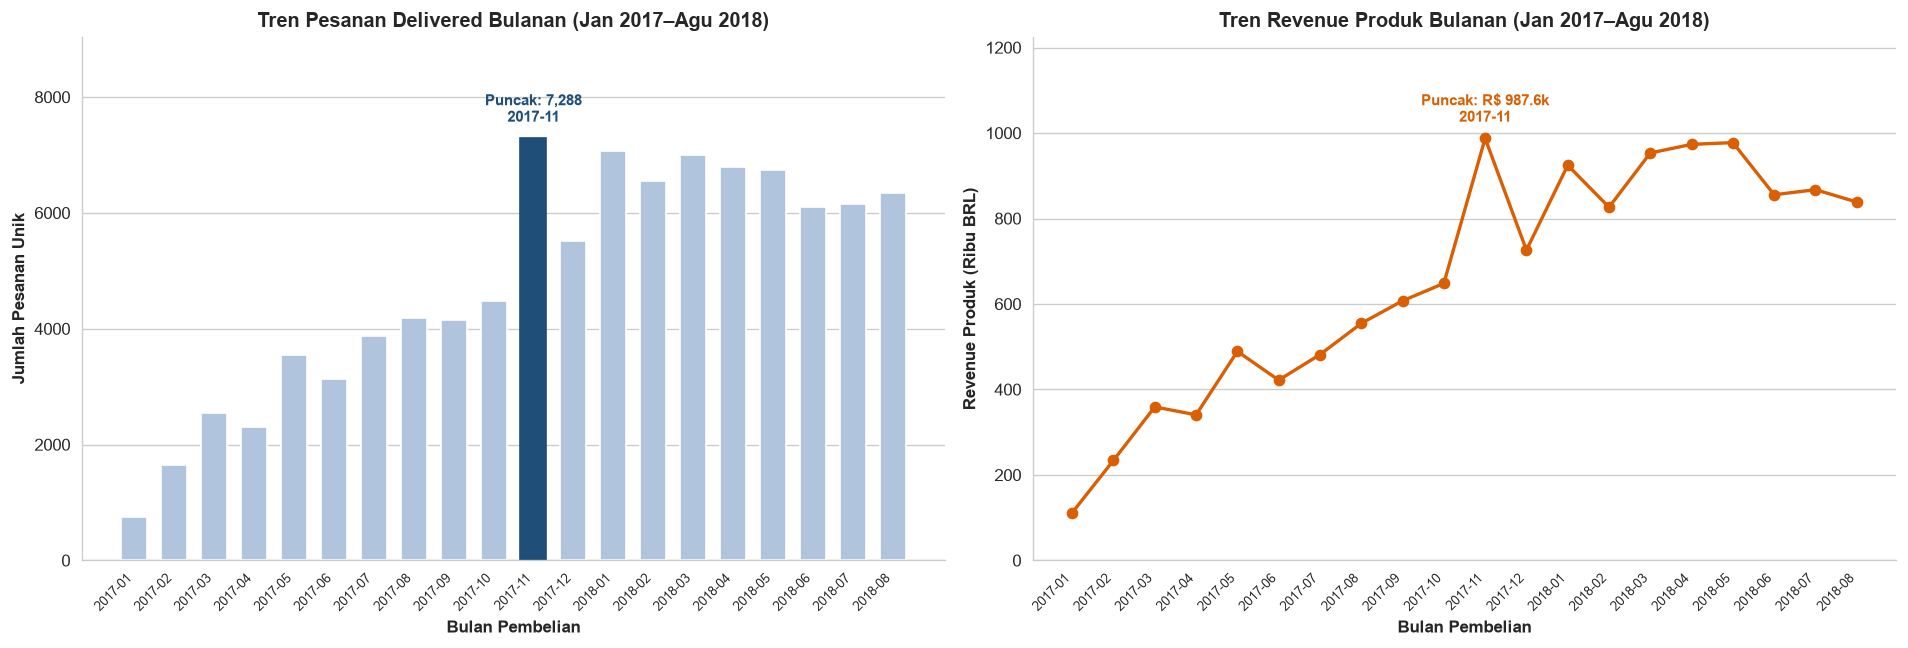

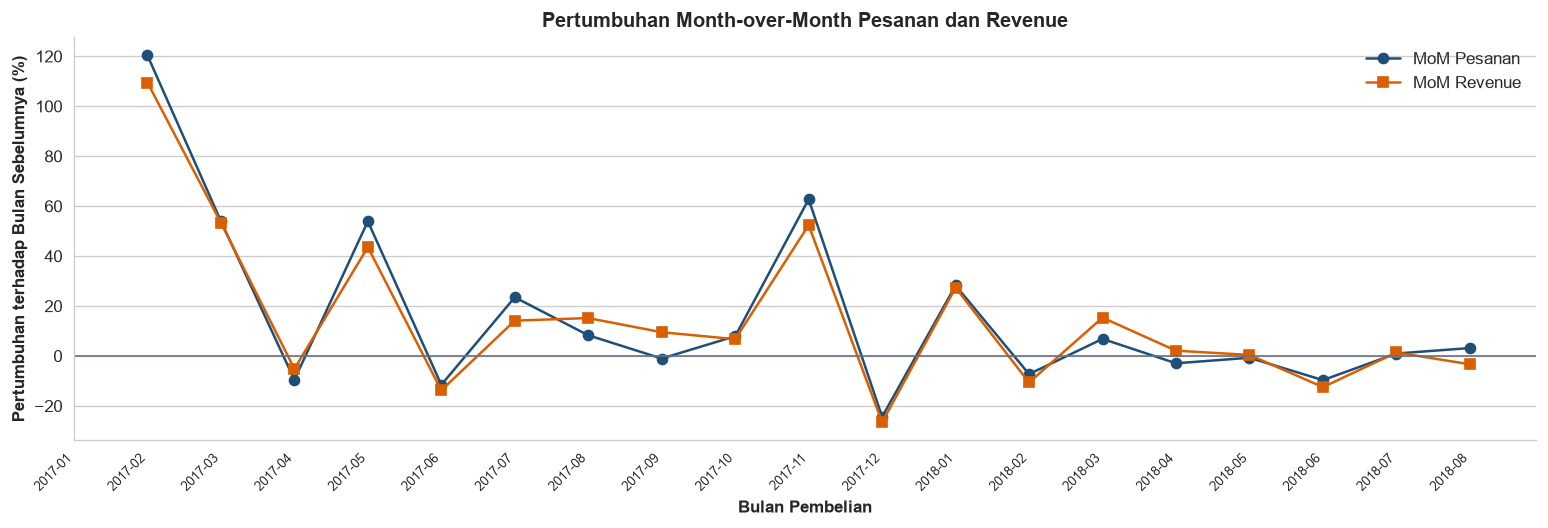

In [14]:
# Volume dan revenue memiliki subplot dengan satuan masing-masing
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(monthly_perf_df))
peak_pos = int(monthly_perf_df["total_orders"].to_numpy().argmax())
peak_orders = monthly_perf_df.iloc[peak_pos]["total_orders"]
bars = axes[0].bar(x, monthly_perf_df["total_orders"], color="#B0C4DE", width=0.65)
bars[peak_pos].set_color("#1F4E78")
axes[0].annotate(f"Puncak: {peak_orders:,}\n{monthly_perf_df.iloc[peak_pos]['year_month']}",
                 xy=(peak_pos, peak_orders), xytext=(0, 10), textcoords="offset points",
                 ha="center", fontsize=9, fontweight="bold", color="#1F4E78")
axes[0].set_ylim(0, peak_orders * 1.24)
axes[0].set_ylabel("Jumlah Pesanan Unik", fontweight="bold")
axes[0].set_title("Tren Pesanan Delivered Bulanan (Jan 2017–Agu 2018)", fontweight="bold")
revenue_k = monthly_perf_df["total_revenue"] / 1e3
peak_revenue_pos = int(revenue_k.to_numpy().argmax())
axes[1].plot(x, revenue_k, color="#D95F02", marker="o", linewidth=2)
axes[1].annotate(f"Puncak: R$ {revenue_k.iloc[peak_revenue_pos]:,.1f}k\n{monthly_perf_df.iloc[peak_revenue_pos]['year_month']}",
                 xy=(peak_revenue_pos, revenue_k.iloc[peak_revenue_pos]),
                 xytext=(0, 10), textcoords="offset points", ha="center",
                 fontsize=9, fontweight="bold", color="#D95F02")
axes[1].set_ylim(0, revenue_k.max() * 1.24)
axes[1].set_ylabel("Revenue Produk (Ribu BRL)", fontweight="bold")
axes[1].set_title("Tren Revenue Produk Bulanan (Jan 2017–Agu 2018)", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Bulan Pembelian", fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(monthly_perf_df["year_month"], rotation=45, ha="right", fontsize=8)
    ax.grid(axis="x", visible=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

# MoM menggunakan satuan persentase yang sebanding dan garis acuan nol
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(x, monthly_perf_df["mom_order_growth_pct"], marker="o", color="#1F4E78", label="MoM Pesanan")
ax.plot(x, monthly_perf_df["mom_revenue_growth_pct"], marker="s", color="#D95F02", label="MoM Revenue")
ax.axhline(0, color="#667085", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(monthly_perf_df["year_month"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Pertumbuhan terhadap Bulan Sebelumnya (%)", fontweight="bold")
ax.set_xlabel("Bulan Pembelian", fontweight="bold")
ax.set_title("Pertumbuhan Month-over-Month Pesanan dan Revenue", fontweight="bold")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

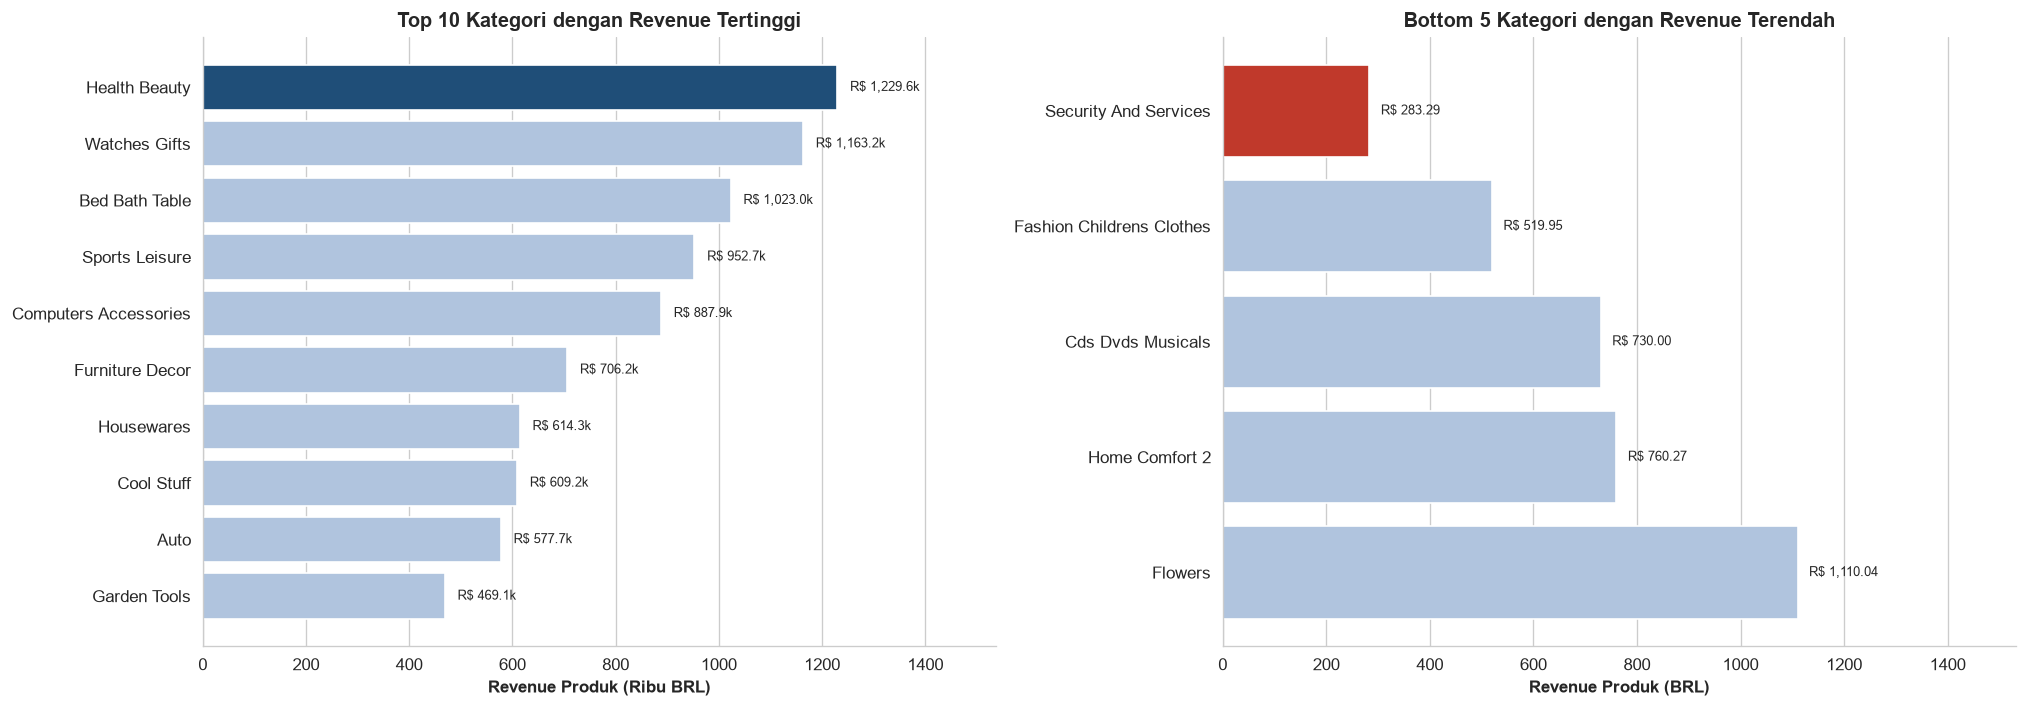

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
top10_cat = category_perf_df.head(10).sort_values("total_revenue")
bottom5_cat = category_perf_df.tail(5).sort_values("total_revenue", ascending=False)
top_colors = ["#1F4E78" if value == top10_cat["total_revenue"].max() else "#B0C4DE"
              for value in top10_cat["total_revenue"]]
axes[0].barh(top10_cat["product_category_name_english"], top10_cat["total_revenue"] / 1e3, color=top_colors)
axes[0].set_xlim(0, top10_cat["total_revenue"].max() / 1e3 * 1.25)
axes[0].set_xlabel("Revenue Produk (Ribu BRL)", fontweight="bold")
axes[0].set_title("Top 10 Kategori dengan Revenue Tertinggi", fontweight="bold")
for i, value in enumerate(top10_cat["total_revenue"] / 1e3):
    axes[0].text(value + top10_cat["total_revenue"].max() / 1e3 * 0.02, i,
                 f"R$ {value:,.1f}k", va="center", fontsize=8)
bottom_colors = ["#C0392B" if value == bottom5_cat["total_revenue"].min() else "#B0C4DE"
                 for value in bottom5_cat["total_revenue"]]
axes[1].barh(bottom5_cat["product_category_name_english"], bottom5_cat["total_revenue"], color=bottom_colors)
axes[1].set_xlim(0, bottom5_cat["total_revenue"].max() * 1.38)
axes[1].set_xlabel("Revenue Produk (BRL)", fontweight="bold")
axes[1].set_title("Bottom 5 Kategori dengan Revenue Terendah", fontweight="bold")
for i, value in enumerate(bottom5_cat["total_revenue"]):
    axes[1].text(value + bottom5_cat["total_revenue"].max() * 0.02, i,
                 f"R$ {value:,.2f}", va="center", fontsize=8)
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

**Insight Visualisasi 1:**
- Grafik volume menunjukkan puncak **November 2017 (7.288 pesanan)**; revenue produk pada bulan itu **R$ 987.648,07**. Grafik MoM menunjukkan kenaikan November sebesar **62,8%** pada pesanan dan **52,4%** pada revenue, kemudian penurunan Desember sebesar **24,4%** dan **26,5%**.
- Pada Januari–Agustus 2018, volume berfluktuasi di rentang **6.096–7.069 pesanan/bulan**. Pola merupakan observasi historis dari pesanan delivered yang tersedia.
- Grafik kategori menampilkan kedua ekstrem: **Health Beauty** tertinggi (**R$ 1.229.557,50**) dan **Security And Services** terendah (**R$ 283,29**, 2 pesanan). Unit grafik Top adalah ribu BRL dan Bottom adalah BRL.

### Pertanyaan 2: Bagaimana perbandingan rata-rata skor ulasan dan persentase ulasan negatif antara pesanan delivered yang tiba tepat waktu/lebih awal dan yang terlambat dari tanggal estimasi sepanjang Januari 2017 hingga Agustus 2018, sebagai dasar penentuan prioritas perbaikan pengiriman dan penanganan pesanan terlambat?

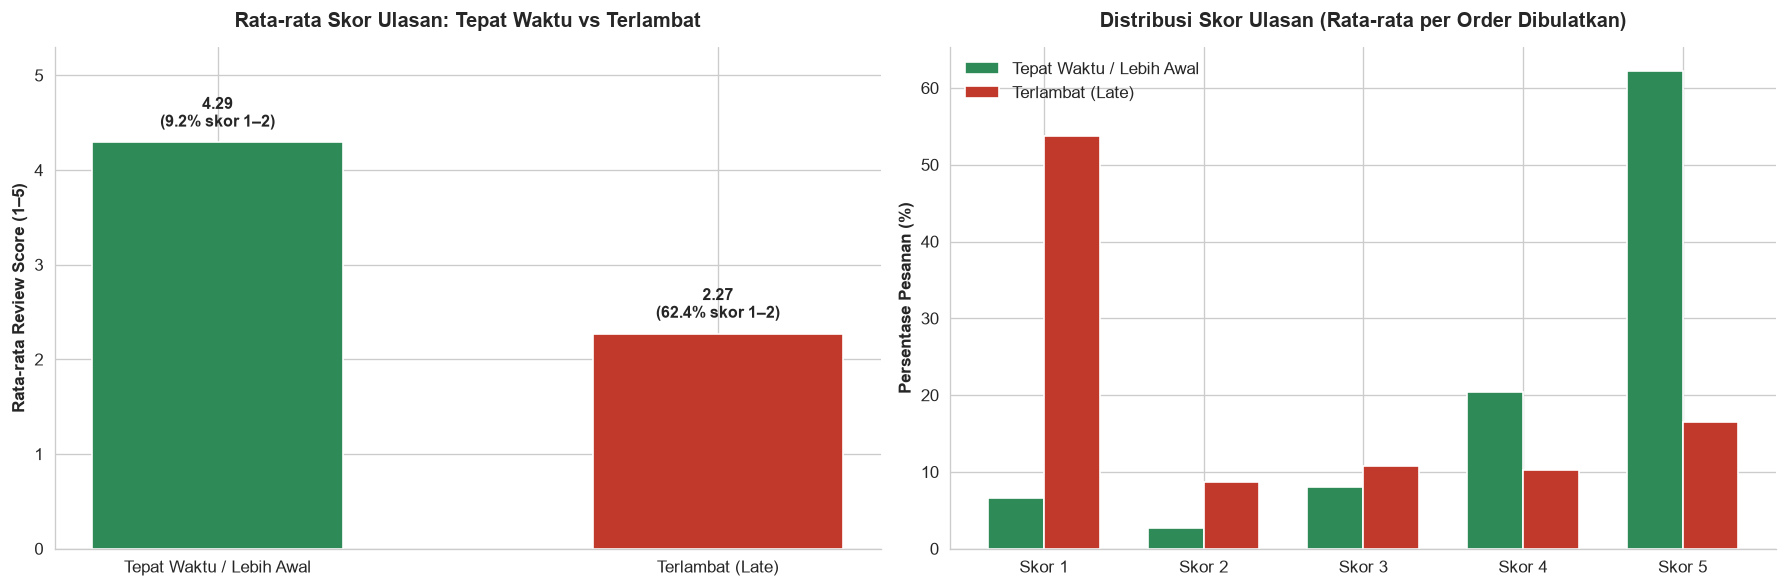

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 2A: Rata-rata Review Score berdasarkan Ketepatan Pengiriman
ax1 = axes[0]
colors_deliv = ["#2E8B57", "#C0392B"]
summary_plot = delivery_review_summary.sort_values("avg_review_score", ascending=False)
bars = ax1.bar(summary_plot["delivery_status"], summary_plot["avg_review_score"], color=colors_deliv, width=0.5)
ax1.set_ylim(0, 5.3)
ax1.set_ylabel("Rata-rata Review Score (1–5)", fontsize=10, fontweight="bold")
ax1.set_title("Rata-rata Skor Ulasan: Tepat Waktu vs Terlambat", fontsize=12, fontweight="bold", pad=12)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

for bar, (_, row) in zip(bars, summary_plot.iterrows()):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.12,
        f"{row['avg_review_score']:.2f}\n({row['negative_review_pct']:.1f}% skor 1–2)",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

# Plot 2B: Distribusi Persentase Review Score (1-5)
ax2 = axes[1]
dist_df = (
    order_level_df.groupby(["delivery_status", "score_int"])["order_id"]
    .count()
    .unstack(fill_value=0)
)
dist_df = dist_df.reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
dist_pct = dist_df.div(dist_df.sum(axis=1), axis=0) * 100
dist_pct = dist_pct.loc[["Tepat Waktu / Lebih Awal", "Terlambat (Late)"]]

x_scores = np.arange(1, 6)
w = 0.35
ax2.bar(x_scores - w/2, dist_pct.loc["Tepat Waktu / Lebih Awal"], width=w, color="#2E8B57", label="Tepat Waktu / Lebih Awal")
ax2.bar(x_scores + w/2, dist_pct.loc["Terlambat (Late)"], width=w, color="#C0392B", label="Terlambat (Late)")
ax2.set_xticks(x_scores)
ax2.set_xticklabels([f"Skor {s}" for s in x_scores])
ax2.set_ylabel("Persentase Pesanan (%)", fontsize=10, fontweight="bold")
ax2.set_title("Distribusi Skor Ulasan (Rata-rata per Order Dibulatkan)", fontsize=12, fontweight="bold", pad=12)
ax2.legend(frameon=False)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Insight Visualisasi 2:**
- Rata-rata skor ulasan adalah **4,29** pada pesanan tepat waktu/lebih awal dan **2,27** pada pesanan terlambat, dengan selisih **2,02 poin**. Proporsi ulasan negatif masing-masing **9,2%** dan **62,4%**. Angka menggunakan skor asli per order dan pembulatan yang sama dengan anotasi grafik.
- Distribusi kelompok tepat waktu didominasi skor 5, sementara kelompok terlambat didominasi skor 1. Pembulatan skor per order ke integer hanya dipakai pada grafik distribusi.
- Diagnostik wilayah mendukung prioritas evaluasi pengiriman pada **AL (21,5% terlambat)**, **MA (17,5%)**, dan **SE (15,4%)** dalam kelompok state dengan ≥100 pesanan. Hasil merupakan perbandingan deskriptif/asosiasi.

## Analisis Lanjutan (Opsional)

### Pertanyaan 3: Bagaimana distribusi segmen pelanggan berdasarkan RFM dengan manual grouping/binning, serta sebaran pelanggan dan kontribusi pendapatan termasuk ongkir per negara bagian selama 2016–2018, sebagai dasar pemilihan target retensi dan alokasi pemasaran wilayah?

RFM dan manual grouping memilih target retensi berdasarkan perilaku transaksi; analisis geospasial membantu alokasi pemasaran dengan memetakan konsentrasi pelanggan serta kontribusi transaksi wilayah.

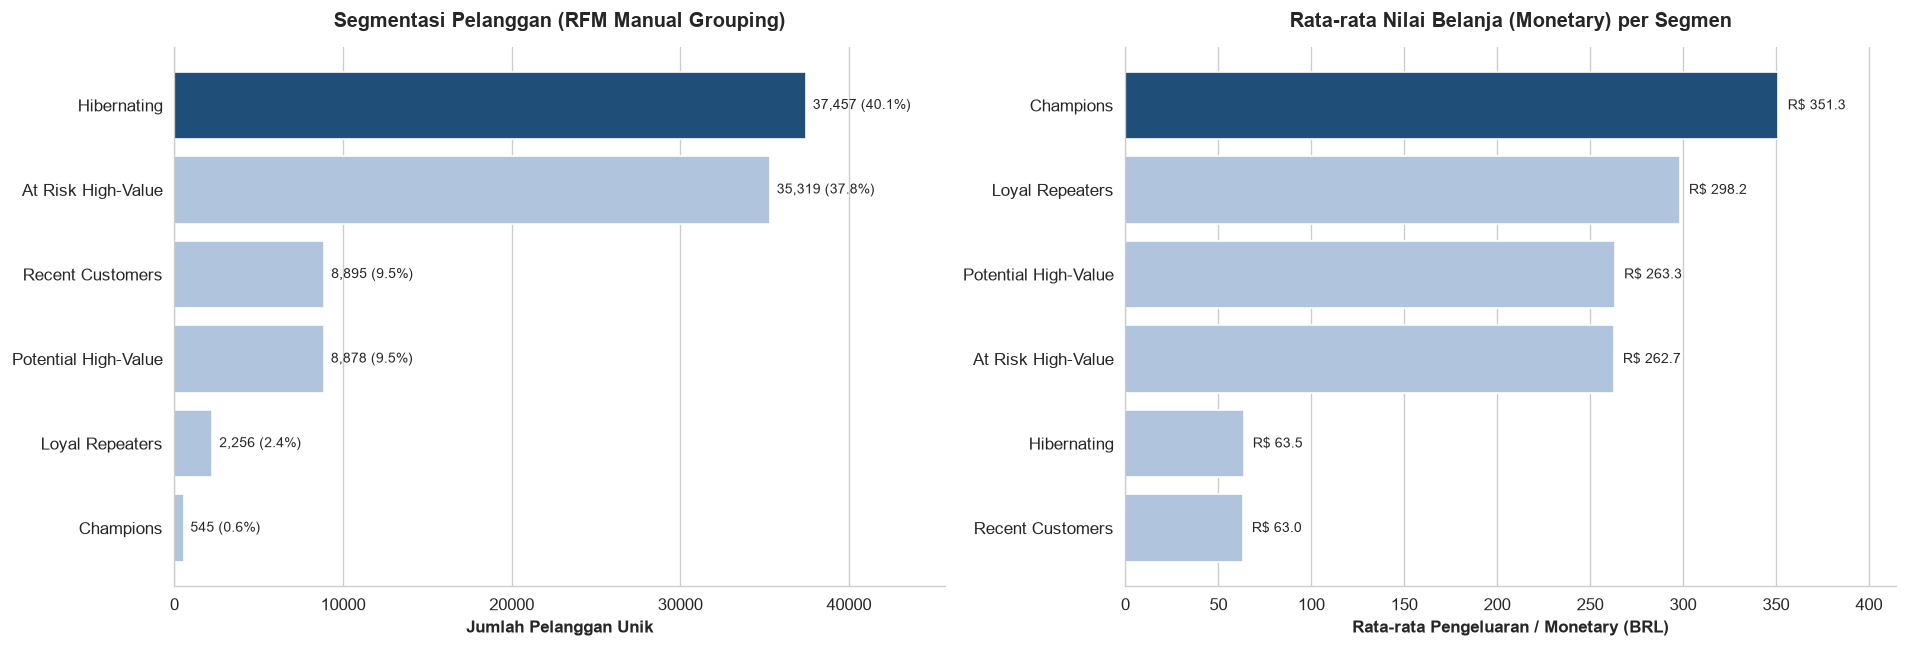

In [17]:
# Visualisasi 3A: RFM Analysis & Customer Segmentation (Manual Grouping)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Bar chart segmen pelanggan
ax1 = axes[0]
seg_plot = segment_summary.sort_values("customer_count", ascending=True)
seg_colors = ["#B0C4DE"] * (len(seg_plot) - 1) + ["#1F4E78"]
ax1.barh(seg_plot["customer_segment"], seg_plot["customer_count"], color=seg_colors)
ax1.set_xlabel("Jumlah Pelanggan Unik", fontsize=10, fontweight="bold")
ax1.set_title("Segmentasi Pelanggan (RFM Manual Grouping)", fontsize=12, fontweight="bold", pad=12)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.set_xlim(0, seg_plot["customer_count"].max() * 1.22)
ax1.grid(axis="y", visible=False)

for i, (_, row) in enumerate(seg_plot.iterrows()):
    ax1.text(row["customer_count"] + 400, i, f"{row['customer_count']:,} ({row['customer_pct']:.1f}%)", va="center", fontsize=8.5)

# Rata-rata Monetary per Segmen
ax2 = axes[1]
seg_mon = segment_summary.sort_values("avg_monetary", ascending=True)
mon_colors = ["#1F4E78" if value == seg_mon["avg_monetary"].max() else "#B0C4DE"
              for value in seg_mon["avg_monetary"]]
ax2.barh(seg_mon["customer_segment"], seg_mon["avg_monetary"], color=mon_colors)
ax2.set_xlabel("Rata-rata Pengeluaran / Monetary (BRL)", fontsize=10, fontweight="bold")
ax2.set_title("Rata-rata Nilai Belanja (Monetary) per Segmen", fontsize=12, fontweight="bold", pad=12)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_xlim(0, seg_mon["avg_monetary"].max() * 1.18)
ax2.grid(axis="y", visible=False)

for i, val in enumerate(seg_mon["avg_monetary"]):
    ax2.text(val + 5, i, f"R$ {val:,.1f}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

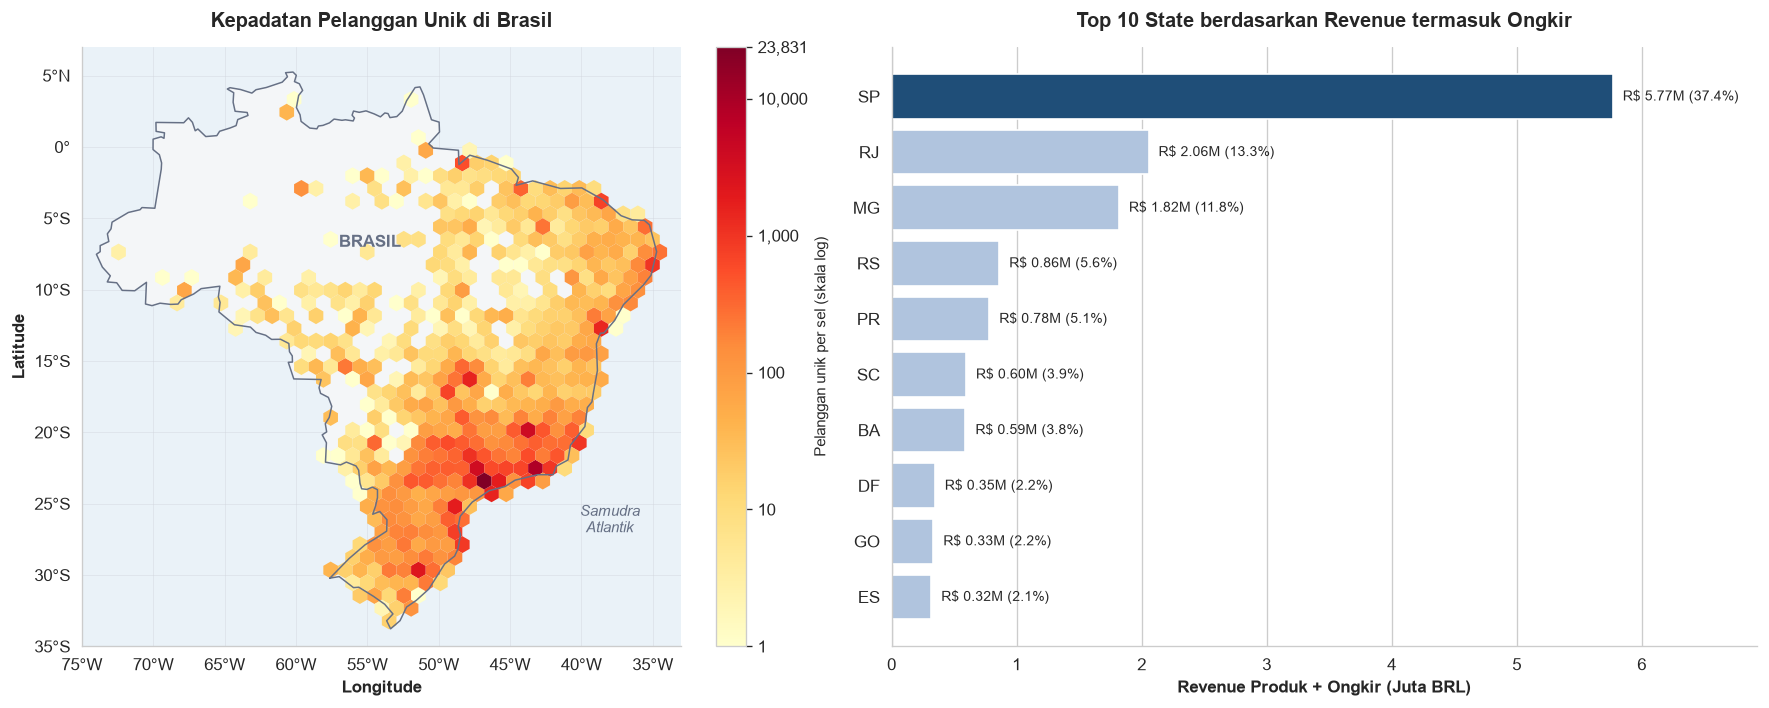

In [18]:
# Visualisasi 3B: Kepadatan pelanggan unik dan kontribusi transaksi per state
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Populasi pelanggan dengan koordinat valid telah disiapkan saat Cleaning
ax1 = axes[0]
mapped_customers = draw_customer_density_map(ax1, geo_ready_customer_df)
ax1.set_title("Kepadatan Pelanggan Unik di Brasil", fontsize=12, fontweight="bold", pad=12)

# Top 10 State berdasarkan Revenue
ax2 = axes[1]
top10_states = state_summary.head(10).sort_values("total_revenue", ascending=True)
state_colors = ["#B0C4DE"] * 9 + ["#1F4E78"]
ax2.barh(top10_states["customer_state"], top10_states["total_revenue"] / 1e6, color=state_colors)
ax2.set_xlabel("Revenue Produk + Ongkir (Juta BRL)", fontsize=10, fontweight="bold")
ax2.set_title("Top 10 State berdasarkan Revenue termasuk Ongkir", fontsize=12, fontweight="bold", pad=12)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_xlim(0, top10_states["total_revenue"].max() / 1e6 * 1.2)
ax2.grid(axis="y", visible=False)

for i, (_, row) in enumerate(top10_states.iterrows()):
    ax2.text(
        row["total_revenue"] / 1e6 + 0.08,
        i,
        f"R$ {row['total_revenue']/1e6:.2f}M ({row['revenue_share_pct']:.1f}%)",
        va="center", fontsize=8.5
    )

plt.tight_layout()
plt.show()

**Insight Visualisasi 3:**
- **RFM/manual grouping:** Hibernating merupakan kelompok terbesar (**40,13%**), diikuti At Risk High-Value (**37,84%**), Recent Customers (**9,53%**), Potential High-Value (**9,51%**), Loyal Repeaters (**2,42%**), dan Champions (**0,58%**). Empat kelompok pembeli satu kali bersama-sama mencakup **97,0%** pelanggan.
- Rata-rata Monetary: **Champions R$ 351,3**, **Loyal Repeaters R$ 298,2**, **Potential High-Value R$ 263,3**, dan **At Risk High-Value R$ 262,7**. Biru tua menandai hanya nilai metrik tertinggi pada setiap grafik.
- **Geografis:** Sel lebih gelap menunjukkan lebih banyak pelanggan unik. Peta mencakup **93.095 dari 93.350 pelanggan** berdasarkan lokasi kode pos terakhir yang valid, dengan batas Brasil dari Natural Earth. **SP (37,4%)**, **RJ (13,3%)**, dan **MG (11,8%)** berkontribusi **62,5%** dari pendapatan termasuk ongkir, sehingga menjadi wilayah penting dalam alokasi pemasaran.

## Conclusion

### Kesimpulan
1. **Tren Penjualan & Kategori Produk (Pertanyaan 1):**
   Volume delivered berfluktuasi dan mencapai puncak historis **November 2017 (7.288 pesanan; revenue produk R$ 987.648,07)**. MoM November adalah **+62,8% pesanan** dan **+52,4% revenue**, disusul **−24,4%** dan **−26,5%** pada Desember. Pertumbuhan persentase pesanan tertinggi terjadi pada Februari 2017 (**+120,4%**) dari basis Januari yang kecil; volume Januari–Agustus 2018 berada pada **6.096–7.069 pesanan/bulan**. **Health Beauty** memberi revenue tertinggi (**R$ 1.229.557,50**), sedangkan **Security And Services** terendah (**R$ 283,29**, 2 pesanan). Temuan mendukung prioritas kategori promosi dan pemantauan stok mengikuti perubahan MoM.
2. **Ketepatan Pengiriman & Kepuasan Pelanggan (Pertanyaan 2):**
   Pada Januari 2017–Agustus 2018, rata-rata ulasan **89.182 pesanan tepat waktu/lebih awal** adalah **4,29**, sedangkan **6.378 pesanan terlambat** adalah **2,27** (selisih **2,02 poin**). Proporsi ulasan negatif masing-masing **9,2%** dan **62,4%**. Perbandingan memakai satu skor per order dengan batas tanggal kalender. Diagnostik wilayah menunjukkan rate keterlambatan **AL 21,5%**, **MA 17,5%**, dan **SE 15,4%** pada state dengan ≥100 pesanan, sehingga menjadi prioritas evaluasi proses pengiriman. Hasil bersifat deskriptif/asosiasi.
3. **Segmentasi Pelanggan RFM & Sebaran Geografis (Pertanyaan 3):**
   Distribusi 93.350 pelanggan adalah **Hibernating 40,13% (37.457)**, **At Risk High-Value 37,84% (35.319)**, **Recent Customers 9,53% (8.895)**, **Potential High-Value 9,51% (8.878)**, **Loyal Repeaters 2,42% (2.256)**, dan **Champions 0,58% (545)**; persentase dibulatkan dua desimal. Empat segmen pertama adalah pembeli satu kali (**97,0%**), sedangkan pelanggan berulang mencakup **3,0%**. Monetary tertinggi adalah Champions (**R$ 351,3**). Secara geografis, kontribusi pendapatan termasuk ongkir terbesar berasal dari **SP 37,4%**, **RJ 13,3%**, dan **MG 11,8%** (total **62,5%**). Segmentasi mendukung pemilihan target retensi dan kontribusi wilayah mendukung alokasi pemasaran.

### Rekomendasi (*Action Items*)
1. **Stok dan fokus promosi:** Prioritaskan evaluasi ketersediaan stok serta alokasi promosi pada Health Beauty, Watches Gifts, dan Bed Bath Table berdasarkan kontribusi revenue. Pantau perubahan MoM untuk menyesuaikan kapasitas bulanan. Evaluasi stok/eksposur kategori rendah seperti Security And Services melalui uji promosi kecil dengan mempertimbangkan volume 2 pesanan.
2. **Prioritas evaluasi pengiriman:** Telusuri pesanan terlambat di AL (85/396), MA (125/713), dan SE (51/332) karena rate-nya paling tinggi dalam ranking yang memenuhi ≥100 pesanan. Bandingkan realisasi dan estimasi per pesanan; di AL rata-ratanya 24,48 vs 33,12 hari dan di MA 21,47 vs 30,89 hari. Tindak lanjuti kelompok terlambat dengan notifikasi pelanggan dan evaluasi proses, lalu ukur perubahan rate keterlambatan serta proporsi ulasan negatif pada kohort berikutnya.
3. **Program Retensi Berbasis Segmen RFM:**
   - Luncurkan program loyalitas/poin khusus untuk segmen **Champions** dan **Loyal Repeaters** guna mempertahankan tingkat retensi.
   - Uji kampanye reaktivasi untuk **35.319 At Risk High-Value** (rata-rata belanja **R$ 262,7** dan recency >90 hari) serta insentif pembelian kedua untuk **8.878 Potential High-Value**. Pantau repeat purchase untuk mengevaluasi hasil program.
   - Gunakan kontribusi transaksi SP/RJ/MG (62,5%) sebagai dasar awal alokasi pemasaran wilayah, lalu evaluasi hasil kampanye dengan metrik konversi/revenue baru.